# Analiza cantitativă a piețelor de energie — Cursul 2: Prognoza prețurilor energiei electrice
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București; Academia Română, Institutul de Prognoză Economică

Acest notebook Jupyter reproduce prognozele, numerele și graficele din Cursul 2 pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Încercați singuri* de pe diapozitive.

**Reguli folosite peste tot.** Prognoza pentru ziua de livrare *d* se face la ora 12:00 CET în ziua *d−1*: prețurile sînt cunoscute pînă în *d−1*, consumul, producția eoliană, solară, hidro, nucleară și fluxurile realizate numai pînă în *d−2*, carbonul la închiderea din *d−2*. Ordine cronologică, fără amestecarea datelor, fără eșantion de validare aleator; orice transformare se estimează în fereastra de calibrare. Valorile inițiale (seed) sînt fixate.

## §1 Date, setul de informații și motorul de prognoză

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, json, time, warnings
from scipy import stats
from joblib import Parallel, delayed
from statsmodels.regression.quantile_regression import QuantReg
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
TZ = 'Europe/Brussels'
SEED = 20261105

PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
G = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
CB = pd.read_csv(DATA + 'crossborder_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', index_col=0)
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', index_col=0)
EUA = pd.read_csv(DATA + 'eua_daily.csv', parse_dates=['date']).set_index('date')['eua_etc_co2l_eur_per_unit']
raw_last = min(PD['RO'].dropna().index.max(), G['hydro_run_of_river'].dropna().index.max())
END = pd.Timestamp(((raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2022-01-01')
print('cut-off (last complete month):', END.date())

cut-off (last complete month): 2026-10-31


**Panelul.** Un rînd pe zi de livrare CET, 24 de coloane orare (după 1 octombrie 2025, fiecare oră este media celor patru sferturi de oră). Convenția DST din tema 1: ora lipsă din martie este media orelor vecine, ora dublată din octombrie este mediată.

panel 2022-01-01 - 2026-10-31 1765 days | test 2025-11-01 - 2026-10-31 | burn-in from 2025-05-03 | DST days in test: [datetime.date(2026, 3, 29), datetime.date(2026, 10, 25)]


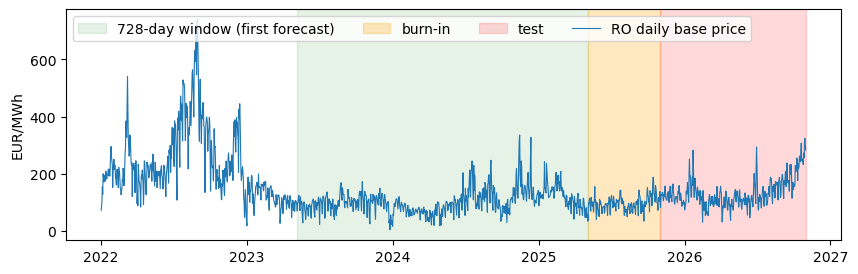

In [2]:
def day_matrix(s):
    """UTC-indexed hourly series -> CET delivery day x 24 hours (Assignment 1 / epftoolbox DST convention) + DST flag."""
    s = s.copy()
    s.index = pd.to_datetime(s.index, utc=True).tz_convert(TZ)
    df = pd.DataFrame({"v": s.values, "day": s.index.tz_localize(None).normalize(), "h": s.index.hour})
    m = df.groupby(["day", "h"])["v"].mean().unstack("h").reindex(columns=range(24))     # 25-h day: doubled hour averaged
    days = m.index
    nh = ((((days + pd.Timedelta(days=1)).tz_localize(TZ)) - days.tz_localize(TZ)) / pd.Timedelta(hours=1)).astype(int)
    dst = pd.Series(np.asarray(nh != 24), index=days)
    for dd in days[dst.values]:
        if pd.isna(m.loc[dd, 2]):
            m.loc[dd, 2] = 0.5 * (m.loc[dd, 1] + m.loc[dd, 3])                              # 23-h day: h02 = mean(h01, h03)
    m = m.dropna(how="any")
    return m, dst.reindex(m.index)


PM, DST = day_matrix(HP['RO'].dropna())
LM, _ = day_matrix(GH['load'].dropna())
RM, _ = day_matrix((GH['wind_onshore'] + GH['solar']).dropna())
CAL = pd.date_range(START, END, freq='D')
PM, LM, RM, DST = PM.reindex(CAL), LM.reindex(CAL), RM.reindex(CAL), DST.reindex(CAL)
assert not PM.isna().any().any() and not LM.isna().any().any() and not RM.isna().any().any()
# daily fundamentals: value usable for day d = last observation on or before d-2 (past only)
CAL_EX = pd.date_range(START - pd.Timedelta(days=30), END, freq='D')
FUND_RAW = pd.DataFrame({'hydro': (G['hydro_run_of_river'] + G['hydro_water_reservoir']).reindex(CAL_EX),
                         'nuclear': G['nuclear'].reindex(CAL_EX), 'netimp': CB['sum'].reindex(CAL_EX),
                         'eua': EUA.reindex(CAL_EX)})
FUND_AVAIL = FUND_RAW.ffill().shift(2).reindex(CAL)
N_TEST, N_BURN = 365, 182
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq='D'); TDAYS = pd.date_range(TEST0, END, freq='D')
P_, L_, R_, F_ = (x.values.astype(float) for x in (PM, LM, RM, FUND_AVAIL))
DOW = CAL.dayofweek.values; IDX = {t: i for i, t in enumerate(CAL)}
PLAGS, XLAGS = (1, 2, 3, 7), (2, 3, 7)
print('panel', CAL[0].date(), '-', CAL[-1].date(), len(CAL), 'days | test', TEST0.date(), '-', END.date(),
      '| burn-in from', FC0.date(), '| DST days in test:', [t.date() for t in TDAYS[DST.loc[TDAYS].values]])
daily = PM.mean(1)
fig, ax = plt.subplots(figsize=(10, 3))
ax.axvspan(FC0 - pd.Timedelta(days=728), FC0, color='g', alpha=0.1, label='728-day window (first forecast)')
ax.axvspan(FC0, TEST0, color='orange', alpha=0.25, label='burn-in'); ax.axvspan(TEST0, END, color='r', alpha=0.15, label='test')
ax.plot(daily, lw=0.8, label='RO daily base price'); ax.set_ylabel('EUR/MWh'); ax.legend(ncol=4, loc='upper left'); plt.show()

**Modelele** (funcții copiate din `analysis_L2.py`): naiv și naiv sezonier, ARX expert (specificația din tema 1) pentru șase ferestre și patru variante, LEAR cu 247 de regresori și $\lambda$ ales prin AIC, gradient boosting și o rețea neuronală cu 24 de ieșiri, reestimate lunar. Fiecare funcție folosește numai rîndurile disponibile la închiderea porții; §10 verifică acest lucru.

In [3]:
ARX_W = (56, 84, 112, 714, 721, 728)
LEAR_W = (364, 546, 728)
GBM_NAMES = ['P(d-1,h)', 'P(d-2,h)', 'P(d-3,h)', 'P(d-7,h)', 'P(d-1,23)', 'min P(d-1)', 'max P(d-1)', 'mean P(d-1)',
             'L(d-2,h)', 'L(d-7,h)', 'RES(d-2,h)', 'RES(d-7,h)', 'mean L(d-2)', 'mean RES(d-2)', 'hydro(d-2)', 'nuclear(d-2)',
             'net imports(d-2)', 'EUA(d-2)', 'hour', 'day of week']


def shift_rows(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def mad_scale(x):
    x = np.asarray(x, float).ravel()
    m = np.median(x)
    s = stats.median_abs_deviation(x, scale="normal")
    return m, (s if s > 0 else 1.0)


def arx_day(Pa, La, Ra, Fa, i, T, kind="asinh"):
    """Expert ARX (Assignment 1, Ziel & Weron 2018 style), one regression per hour; target day = row i.
    Calibration targets rows i-T..i-1; VST median/MAD from price rows i-T-7..i-1; L,R z-scores from rows i-T-7..i-2."""
    P1, P2, P7 = shift_rows(Pa, 1), shift_rows(Pa, 2), shift_rows(Pa, 7)
    lo = i - T
    if kind == "raw":
        m, s = 0.0, 1.0
        f = lambda x: x  # noqa: E731
        finv = f
    else:
        m, s = mad_scale(Pa[lo - 7:i])
        f = lambda x: np.arcsinh((x - m) / s)  # noqa: E731
        finv = lambda y: m + s * np.sinh(y)  # noqa: E731
    rows = slice(lo, i + 1)
    Y, Y1, Y2, Y7 = f(Pa[rows]), f(P1[rows]), f(P2[rows]), f(P7[rows])
    mu_l, sd_l = np.mean(La[lo - 7:i - 1]), np.std(La[lo - 7:i - 1])
    mu_r, sd_r = np.mean(Ra[lo - 7:i - 1]), np.std(Ra[lo - 7:i - 1])
    Lz = (shift_rows(La, 2)[rows] - mu_l) / sd_l
    Rz = (shift_rows(Ra, 2)[rows] - mu_r) / sd_r
    dw = DOW[rows]
    dmy = np.column_stack([dw == 0, dw == 5, dw == 6]).astype(float)
    extra = None
    if kind == "fund":
        Fr = Fa[rows]
        extra = (Fr - np.nanmean(Fr[:-1], axis=0)) / np.nanstd(Fr[:-1], axis=0)
    n = T + 1
    out, coefs = np.zeros(24), np.zeros((24, 12))
    if kind == "single":                                          # one pooled regression, common slopes, hour intercepts
        Xs, ys = [], []
        for h in range(24):
            hd = np.zeros((n, 24))
            hd[:, h] = 1
            Xs.append(np.column_stack([hd, Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1), Lz[:, h], Rz[:, h], dmy]))
            ys.append(Y[:, h])
        Xs, ys = np.stack(Xs, 1), np.stack(ys, 1)                 # n x 24 x p
        Xc, yc = Xs[:-1].reshape(-1, Xs.shape[2]), ys[:-1].ravel()
        b = np.linalg.lstsq(Xc, yc, rcond=None)[0]
        return finv(Xs[-1] @ b), None
    for h in range(24):
        cols = [np.ones(n), Y1[:, h], Y2[:, h], Y7[:, h], Y1[:, 23], Y1.min(1), Y1.max(1)]
        if kind != "noexog":
            cols += [Lz[:, h], Rz[:, h]]
        cols += [dmy[:, 0], dmy[:, 1], dmy[:, 2]]
        X = np.column_stack(cols)
        if h == 23:
            X = np.delete(X, 4, axis=1)                           # Y_{d-1,23} appears twice for h = 23
        if extra is not None:
            X = np.column_stack([X, extra])
        b = np.linalg.lstsq(X[:-1], Y[:-1, h], rcond=None)[0]
        out[h] = X[-1] @ b
        if kind == "asinh" and h != 23 and X.shape[1] == 12:
            coefs[h] = b
    return finv(out), coefs


def lear_design(Pa, La, Ra, lo, i):
    """LEAR regressors (Assignment 1: 247 columns) for rows lo..i, with transforms fitted on rows available at gate closure."""
    m, s = mad_scale(Pa[lo - 7:i])
    mL, sL = mad_scale(La[lo - 7:i - 1])
    mR, sR = mad_scale(Ra[lo - 7:i - 1])
    rows = slice(lo, i + 1)
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks.append(np.eye(7)[DOW[rows]])
    X = np.column_stack(blocks)
    Y = np.arcsinh((Pa[rows] - m) / s)
    return X, Y, m, s


def lear_day(Pa, La, Ra, i, T):
    from sklearn.linear_model import LassoLarsIC
    lo = i - T
    X, Y, m, s = lear_design(Pa, La, Ra, lo, i)
    mu, sd = X[:-1].mean(0), X[:-1].std(0)
    sd[sd == 0] = 1.0
    Xs = (X - mu) / sd
    out, nz = np.zeros(24), np.zeros((24, X.shape[1]), bool)
    for h in range(24):
        mdl = LassoLarsIC(criterion="aic", max_iter=2000).fit(Xs[:-1], Y[:-1, h])
        out[h] = mdl.predict(Xs[-1:])[0]
        nz[h] = mdl.coef_ != 0
    return m + s * np.sinh(out), nz


def point_day(Pa, La, Ra, Fa, i, lear=True):
    """All classical point forecasts for target row i."""
    r = {"naive": Pa[i - 7] if DOW[i] in (0, 5, 6) else Pa[i - 1], "snaive": Pa[i - 7]}
    for T in ARX_W:
        r[f"arx{T}"], c = arx_day(Pa, La, Ra, Fa, i, T)
        if T == 728:
            r["arx_coef"] = c
    r["arx728_raw"] = arx_day(Pa, La, Ra, Fa, i, 728, "raw")[0]
    r["arx728_noexog"] = arx_day(Pa, La, Ra, Fa, i, 728, "noexog")[0]
    r["arx728_fund"] = arx_day(Pa, La, Ra, Fa, i, 728, "fund")[0]
    r["arx728_single"] = arx_day(Pa, La, Ra, Fa, i, 728, "single")[0]
    if lear:
        for T in LEAR_W:
            r[f"lear{T}"], nz = lear_day(Pa, La, Ra, i, T)
            if T == 728:
                r["lear_nz"] = nz
    return r


def run_chunk(Pa, La, Ra, Fa, ii):
    return {i: point_day(Pa, La, Ra, Fa, i) for i in ii}


def gbm_rows(Pa, La, Ra, Fa, rows):
    """Long-format features for (day, hour) pairs: same-hour lags, daily aggregates, fundamentals, calendar."""
    P1, P2, P3, P7 = (shift_rows(Pa, k) for k in PLAGS)
    L2, L7, R2, R7 = shift_rows(La, 2), shift_rows(La, 7), shift_rows(Ra, 2), shift_rows(Ra, 7)
    feats = []
    for h in range(24):
        f = np.column_stack([P1[rows, h], P2[rows, h], P3[rows, h], P7[rows, h], P1[rows, 23], P1[rows].min(1), P1[rows].max(1),
                             P1[rows].mean(1), L2[rows, h], L7[rows, h], R2[rows, h], R7[rows, h], L2[rows].mean(1),
                             R2[rows].mean(1), Fa[rows], np.full(len(rows), h), DOW[rows]])
        feats.append(f)
    return np.stack(feats, 1)


def gbm_month(Pa, La, Ra, Fa, i0, i1, seed=SEED):
    """Fit on targets rows 7..i0-1 (all before the month), forecast rows i0..i1 (the month)."""
    from sklearn.ensemble import HistGradientBoostingRegressor
    tr = np.arange(7, i0)
    m, s = mad_scale(Pa[tr])
    Xtr = gbm_rows(Pa, La, Ra, Fa, tr).reshape(-1, len(GBM_NAMES))
    ytr = np.arcsinh((Pa[tr] - m) / s).ravel()
    mdl = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=40,
                                        l2_regularization=1.0, early_stopping=False, random_state=seed,
                                        categorical_features=[18, 19]).fit(Xtr, ytr)
    te = np.arange(i0, i1 + 1)
    pr = mdl.predict(gbm_rows(Pa, La, Ra, Fa, te).reshape(-1, len(GBM_NAMES))).reshape(len(te), 24)
    return m + s * np.sinh(pr), mdl


def mlp_design(Pa, La, Ra, Fa, rows, m, s, mL, sL, mR, sR):
    blocks = [np.arcsinh((shift_rows(Pa, k)[rows] - m) / s) for k in PLAGS]
    blocks += [np.arcsinh((shift_rows(La, k)[rows] - mL) / sL) for k in XLAGS]
    blocks += [np.arcsinh((shift_rows(Ra, k)[rows] - mR) / sR) for k in XLAGS]
    blocks += [Fa[rows], np.eye(7)[DOW[rows]]]
    return np.column_stack(blocks)


def mlp_month(Pa, La, Ra, Fa, i0, i1, seeds=(1, 2, 3, 4), max_ep=150):
    """Multi-output network (24 outputs, Lago et al. 2021 style DNN, small). Epochs chosen on a CHRONOLOGICAL validation
    block (last 15% of the training days); then refitted on all training days with that number of epochs."""
    from sklearn.neural_network import MLPRegressor
    tr = np.arange(7, i0)
    cut = int(len(tr) * 0.85)
    v0 = tr[cut]                                                # first validation day: transforms frozen at its gate closure
    m0, s0 = mad_scale(Pa[7:v0])
    mL0, sL0 = mad_scale(La[7:v0 - 1])
    mR0, sR0 = mad_scale(Ra[7:v0 - 1])
    X0 = mlp_design(Pa, La, Ra, Fa, tr, m0, s0, mL0, sL0, mR0, sR0)
    Y0 = np.arcsinh((Pa[tr] - m0) / s0)
    m, s = mad_scale(Pa[tr])                                    # final refit: everything available before the month
    mL, sL = mad_scale(La[7:i0 - 1])
    mR, sR = mad_scale(Ra[7:i0 - 1])
    X = mlp_design(Pa, La, Ra, Fa, tr, m, s, mL, sL, mR, sR)
    Y = np.arcsinh((Pa[tr] - m) / s)
    te = np.arange(i0, i1 + 1)
    Xte = mlp_design(Pa, La, Ra, Fa, te, m, s, mL, sL, mR, sR)
    preds, epochs = [], []
    for sd in seeds:
        mu, sg = X0[:cut].mean(0), X0[:cut].std(0)
        sg[sg == 0] = 1
        net = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=1e-3, batch_size=64, random_state=sd)
        best, best_ep = np.inf, 1
        for ep_ in range(1, max_ep + 1):
            net.partial_fit((X0[:cut] - mu) / sg, Y0[:cut])
            v = np.mean(np.abs(m0 + s0 * np.sinh(net.predict((X0[cut:] - mu) / sg)) - Pa[tr[cut:]]))
            if v < best:
                best, best_ep = v, ep_
        mu, sg = X.mean(0), X.std(0)
        sg[sg == 0] = 1
        net = MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, learning_rate_init=1e-3, batch_size=64, random_state=sd)
        for _ in range(best_ep):
            net.partial_fit((X - mu) / sg, Y)
        preds.append(m + s * np.sinh(net.predict((Xte - mu) / sg)))
        epochs.append(best_ep)
    return np.mean(preds, 0), epochs


def month_blocks(days):
    out = []
    for _, g in pd.Series(days, index=days).groupby(days.to_period("M")):
        out.append((IDX[g.index[0]], IDX[g.index[-1]]))
    return out

In [4]:
t0 = time.time()
ii = [IDX[t] for t in FDAYS]
res = Parallel(n_jobs=-1)(delayed(run_chunk)(P_, L_, R_, F_, ii[k::16]) for k in range(16))
allr = {}
for r_ in res: allr.update(r_)
names = [k for k in allr[ii[0]] if k not in ('arx_coef', 'lear_nz')]
PT = {k: np.array([allr[i][k] for i in ii]) for k in names}
ARX_COEF = np.array([allr[i]['arx_coef'] for i in ii]); LEAR_NZ = np.array([allr[i]['lear_nz'] for i in ii])
MB = month_blocks(TDAYS)
G_RES = Parallel(n_jobs=-1)(delayed(gbm_month)(P_, L_, R_, F_, a, b) for a, b in MB)
M_RES = Parallel(n_jobs=-1)(delayed(mlp_month)(P_, L_, R_, F_, a, b) for a, b in MB)
print('engine done in %.0f s' % (time.time() - t0))

POS = {t: k for k, t in enumerate(FDAYS)}; TI = np.array([POS[t] for t in TDAYS])
ACT_F = P_[ii]; A = ACT_F[TI]
PT['aw_arx'] = np.mean([PT[f'arx{T}'] for T in ARX_W], 0); PT['aw_lear'] = np.mean([PT[f'lear{T}'] for T in LEAR_W], 0)
M = {k: v[TI] for k, v in PT.items()}
M['gbm'] = np.vstack([g[0] for g in G_RES]); M['mlp'] = np.vstack([m[0] for m in M_RES])
M['ens_lm'] = 0.5 * (M['aw_lear'] + M['mlp']); M['ens_all'] = np.mean([M['aw_arx'], M['aw_lear'], M['gbm'], M['mlp']], 0)
print('test hours:', A.size, '| mean price %.2f EUR/MWh' % A.mean())

engine done in 329 s
test hours: 8760 | mean price 134.46 EUR/MWh


## §2 Modele de referință, orizonturi, măsuri ale erorii și testul Diebold–Mariano

Mon/Sat/Sun | MAE d-1 33.48 | MAE d-7 29.87
Tue-Fri | MAE d-1 26.27 | MAE d-7 37.83


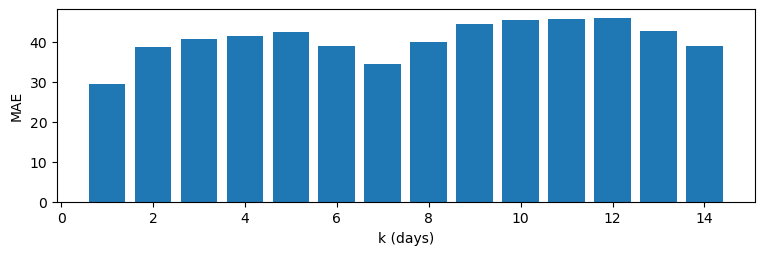

{1: np.float64(29.37), 2: np.float64(38.52), 3: np.float64(40.53), 4: np.float64(41.47), 5: np.float64(42.31), 6: np.float64(38.86), 7: np.float64(34.41), 8: np.float64(39.77), 9: np.float64(44.46), 10: np.float64(45.45), 11: np.float64(45.65), 12: np.float64(45.77), 13: np.float64(42.54), 14: np.float64(38.94)}


In [5]:
dw = TDAYS.dayofweek.values; lag1 = P_[np.array([IDX[t] for t in TDAYS]) - 1]
for nm, msk in [('Mon/Sat/Sun', np.isin(dw, [0, 5, 6])), ('Tue-Fri', ~np.isin(dw, [0, 5, 6]))]:
    print(nm, '| MAE d-1 %.2f | MAE d-7 %.2f' % (np.abs(A[msk] - lag1[msk]).mean(), np.abs(A[msk] - M['snaive'][msk]).mean()))
hz = {k: np.abs(A - P_[np.array([IDX[t] for t in TDAYS]) - k]).mean() for k in range(1, 15)}
plt.figure(figsize=(9, 2.5)); plt.bar(list(hz), list(hz.values())); plt.xlabel('k (days)'); plt.ylabel('MAE'); plt.show()
print({k: round(v, 2) for k, v in hz.items()})

In [6]:
def acc(F):
    e = A - F; den = np.abs(A) + np.abs(F); nz = np.abs(A) > 0
    return {'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()),
            'sMAPE %': (2 * np.abs(e[den > 0]) / den[den > 0]).mean() * 100, 'MAPE %': (np.abs(e[nz]) / np.abs(A[nz])).mean() * 100}
ORDER = ['naive', 'snaive', 'arx56', 'arx84', 'arx112', 'arx714', 'arx721', 'arx728', 'aw_arx', 'arx728_noexog', 'arx728_fund',
         'arx728_raw', 'arx728_single', 'lear364', 'lear546', 'lear728', 'aw_lear', 'gbm', 'mlp', 'ens_lm', 'ens_all']
TAB = pd.DataFrame({k: acc(M[k]) for k in ORDER}).T
TAB['rMAE'] = TAB['MAE'] / TAB.loc['naive', 'MAE']
print(TAB.round(3))

                  MAE    RMSE  sMAPE %    MAPE %   rMAE
naive          27.822  44.539   34.471  3685.462  1.000
snaive         34.408  55.478   39.434  5506.199  1.237
arx56          24.443  40.086   29.995  5780.333  0.879
arx84          23.789  38.915   28.971  6126.240  0.855
arx112         23.414  37.945   28.432  5539.234  0.842
arx714         22.681  36.582   27.776  5052.226  0.815
arx721         22.699  36.556   27.776  5075.095  0.816
arx728         22.715  36.620   27.808  5079.514  0.816
aw_arx         22.303  36.339   27.581  5037.140  0.802
arx728_noexog  22.626  36.490   27.751  5045.025  0.813
arx728_fund    22.722  36.501   28.023  5492.139  0.817
arx728_raw     22.859  35.849   28.381  3839.563  0.822
arx728_single  24.535  37.968   29.499  5884.382  0.882
lear364        22.959  36.804   28.084  6166.985  0.825
lear546        22.730  36.820   27.701  5646.291  0.817
lear728        22.619  36.356   27.684  5920.815  0.813
aw_lear        22.533  36.346   27.659  5777.731

MAPE AW-LEAR 5777.7% | without |P|<5: 32.4% | share from |P|<5: 99.5% (387 hours)


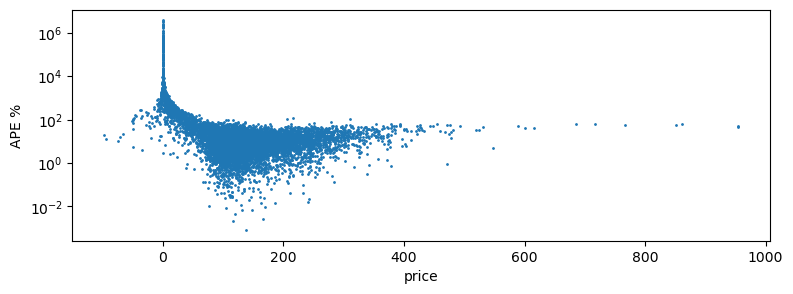

In [7]:
ape = np.abs(A - M['aw_lear']) / np.abs(A); ape[~np.isfinite(ape)] = np.nan; small = np.abs(A) < 5
print('MAPE AW-LEAR %.1f%% | without |P|<5: %.1f%% | share from |P|<5: %.1f%% (%d hours)' % (
      np.nanmean(ape) * 100, np.nanmean(ape[~small]) * 100, np.nansum(ape[small]) / np.nansum(ape) * 100, small.sum()))
plt.figure(figsize=(9, 3)); plt.scatter(A.ravel(), ape.ravel() * 100, s=1); plt.yscale('log'); plt.xlabel('price'); plt.ylabel('APE %'); plt.show()

In [8]:
def nw_var(x, lags=7):
    x = x - x.mean()
    n = len(x)
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    return v


def dm(ea, eb, lags=7):
    dlt = np.mean(np.abs(ea), 1) - np.mean(np.abs(eb), 1)
    stat = dlt.mean() / np.sqrt(nw_var(dlt, lags) / len(dlt))
    return stat, 1 - stats.norm.cdf(stat)


DM_MODELS = ['naive', 'snaive', 'arx728', 'aw_arx', 'lear728', 'aw_lear', 'gbm', 'mlp', 'ens_lm', 'ens_all']
E = {k: A - M[k] for k in ORDER}
DMP = pd.DataFrame([[np.nan if a == b else dm(E[a], E[b])[1] for b in DM_MODELS] for a in DM_MODELS], index=DM_MODELS, columns=DM_MODELS)
print('p-values: is the COLUMN model more accurate than the ROW model?'); print(DMP.round(3))
for a, b in [('naive', 'aw_lear'), ('aw_arx', 'aw_lear'), ('aw_lear', 'ens_all')]:
    print(a, 'vs', b, 'DM = %.2f, p = %.4f' % dm(E[a], E[b]))

p-values: is the COLUMN model more accurate than the ROW model?
         naive  snaive  arx728  aw_arx  lear728  aw_lear    gbm    mlp  \
naive      NaN     1.0   0.000   0.000    0.000    0.000  0.000  0.001   
snaive   0.000     NaN   0.000   0.000    0.000    0.000  0.000  0.000   
arx728   1.000     1.0     NaN   0.023    0.320    0.213  0.999  1.000   
aw_arx   1.000     1.0   0.977     NaN    0.883    0.797  1.000  1.000   
lear728  1.000     1.0   0.680   0.117      NaN    0.164  1.000  1.000   
aw_lear  1.000     1.0   0.787   0.203    0.836      NaN  1.000  1.000   
gbm      1.000     1.0   0.001   0.000    0.000    0.000    NaN  0.989   
mlp      0.999     1.0   0.000   0.000    0.000    0.000  0.011    NaN   
ens_lm   1.000     1.0   0.034   0.002    0.006    0.004  0.970  1.000   
ens_all  1.000     1.0   1.000   0.814    0.998    0.986  1.000  1.000   

         ens_lm  ens_all  
naive     0.000    0.000  
snaive    0.000    0.000  
arx728    0.966    0.000  
aw_arx    0.9

## §3 Modelul expert ARX: coeficienți, variabile exogene, un model pe oră, VST

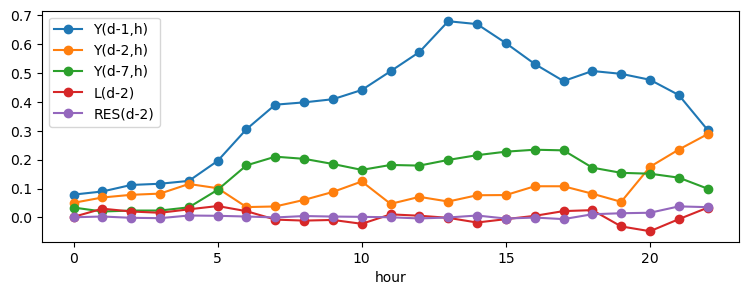

                  MAE    RMSE   rMAE
arx728_noexog  22.626  36.490  0.813
arx728         22.715  36.620  0.816
arx728_fund    22.722  36.501  0.817
arx728_single  24.535  37.968  0.882
arx728_raw     22.859  35.849  0.822
hours where one pooled model is worse: 21 of 24


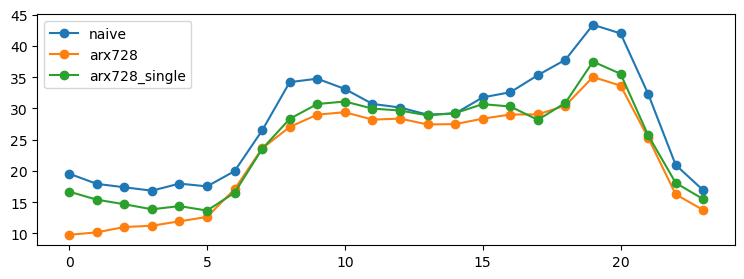

In [9]:
co = ARX_COEF[TI].mean(0)
cnames = ['const', 'Y(d-1,h)', 'Y(d-2,h)', 'Y(d-7,h)', 'Y(d-1,23)', 'Ymin', 'Ymax', 'L(d-2)', 'RES(d-2)', 'Mon', 'Sat', 'Sun']
pd.DataFrame(co[:23], columns=cnames)[['Y(d-1,h)', 'Y(d-2,h)', 'Y(d-7,h)', 'L(d-2)', 'RES(d-2)']].plot(marker='o', figsize=(9, 3)); plt.xlabel('hour'); plt.show()
print(TAB.loc[['arx728_noexog', 'arx728', 'arx728_fund', 'arx728_single', 'arx728_raw'], ['MAE', 'RMSE', 'rMAE']].round(3))
bh = pd.DataFrame({k: np.abs(A - M[k]).mean(0) for k in ['naive', 'arx728', 'arx728_single']})
print('hours where one pooled model is worse:', int((bh['arx728_single'] > bh['arx728']).sum()), 'of 24'); bh.plot(marker='o', figsize=(9, 3)); plt.show()

## §4 LEAR: ce regresori din cei 247 păstrează LASSO?

non-zero coefficients: mean 42.0, min 8, max 121 of 247
P(d-1) same hour      78.8
P(d-1) other hours    34.2
P(d-2)                20.1
P(d-3)                19.0
P(d-7)                22.9
load                   8.6
wind+solar            10.9
day of week           63.9
dtype: float64


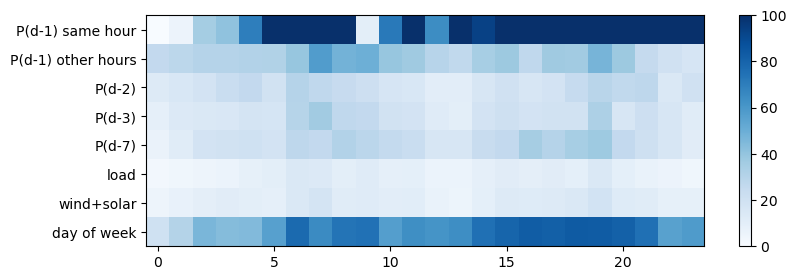

In [10]:
NZ = LEAR_NZ[TI]; nnz = NZ.sum(2)
print('non-zero coefficients: mean %.1f, min %d, max %d of %d' % (nnz.mean(), nnz.min(), nnz.max(), NZ.shape[2]))
groups = {'P(d-1) same hour': [None], 'P(d-1) other hours': [None], 'P(d-2)': range(24, 48), 'P(d-3)': range(48, 72),
          'P(d-7)': range(72, 96), 'load': range(96, 168), 'wind+solar': range(168, 240), 'day of week': range(240, 247)}
SEL = pd.DataFrame(index=groups, columns=range(24), dtype=float)
for g, cols in groups.items():
    for h in range(24):
        c = [h] if g == 'P(d-1) same hour' else ([j for j in range(24) if j != h] if g == 'P(d-1) other hours' else list(cols))
        SEL.loc[g, h] = NZ[:, h, c].mean() * 100
print(SEL.mean(1).round(1)); plt.figure(figsize=(9, 3)); plt.imshow(SEL.values, aspect='auto', cmap='Blues');
plt.yticks(range(len(groups)), list(groups)); plt.colorbar(); plt.show()

## §5 Ferestre de calibrare și combinații

In [11]:
print(TAB.loc[[f'arx{T}' for T in ARX_W] + ['aw_arx'] + [f'lear{T}' for T in LEAR_W] + ['aw_lear'], ['MAE', 'rMAE']].round(3))
TM = TDAYS.to_period('M')
bym = pd.DataFrame({k: [np.abs(A[TM == m] - M[k][TM == m]).mean() for m in sorted(set(TM))] for k in ORDER}, index=sorted(set(TM)))
print('ensemble of 4 better than AW-LEAR in', int((bym['ens_all'] < bym['aw_lear']).sum()), 'of 12 months')
print('scoreboard'); print(TAB.loc[['naive', 'snaive', 'arx56', 'arx728', 'aw_arx', 'arx728_single', 'arx728_raw', 'lear364',
      'lear728', 'aw_lear', 'gbm', 'mlp', 'ens_lm', 'ens_all'], ['MAE', 'RMSE', 'sMAPE %', 'rMAE']].round(3))
nodst = ~DST.loc[TDAYS].values; print('AW-LEAR MAE without DST days: %.2f' % np.abs(A[nodst] - M['aw_lear'][nodst]).mean())

            MAE   rMAE
arx56    24.443  0.879
arx84    23.789  0.855
arx112   23.414  0.842
arx714   22.681  0.815
arx721   22.699  0.816
arx728   22.715  0.816
aw_arx   22.303  0.802
lear364  22.959  0.825
lear546  22.730  0.817
lear728  22.619  0.813
aw_lear  22.533  0.810
ensemble of 4 better than AW-LEAR in 8 of 12 months
scoreboard
                  MAE    RMSE  sMAPE %   rMAE
naive          27.822  44.539   34.471  1.000
snaive         34.408  55.478   39.434  1.237
arx56          24.443  40.086   29.995  0.879
arx728         22.715  36.620   27.808  0.816
aw_arx         22.303  36.339   27.581  0.802
arx728_single  24.535  37.968   29.499  0.882
arx728_raw     22.859  35.849   28.381  0.822
lear364        22.959  36.804   28.084  0.825
lear728        22.619  36.356   27.684  0.813
aw_lear        22.533  36.346   27.659  0.810
gbm            24.050  37.727   28.659  0.864
mlp            25.539  40.054   29.774  0.918
ens_lm         23.118  36.950   28.062  0.831
ens_all        22

## §6 Învățare automată: gradient boosting și o rețea neuronală (introducere la cursul 7)

hours better than AW-LEAR: {'gbm': 0, 'mlp': 0, 'ens_all': 15}
MLP epochs chosen on the chronological validation block: [[18, 19, 60, 13], [20, 19, 16, 52], [17, 20, 16, 14], [21, 22, 18, 16], [15, 23, 19, 18], [15, 16, 15, 18], [20, 19, 18, 23], [19, 21, 20, 30], [20, 23, 14, 23], [22, 31, 15, 28], [26, 26, 22, 59], [27, 54, 50, 21]]


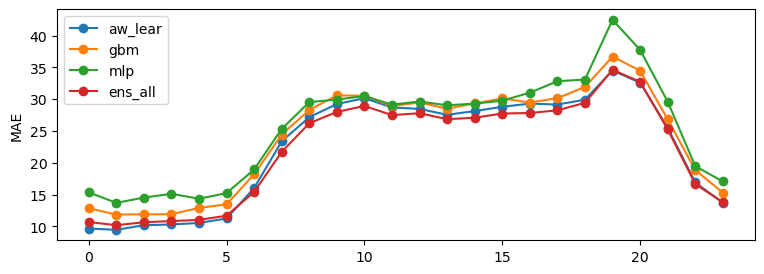

case study C2 (load): MAPE GBM 4.09, Chronos 4.16, MLP 4.58, linear 4.85, SARIMA 8.03, naive 48h 10.17


In [12]:
bh = pd.DataFrame({k: np.abs(A - M[k]).mean(0) for k in ['aw_lear', 'gbm', 'mlp', 'ens_all']})
print('hours better than AW-LEAR:', {k: int((bh[k] < bh['aw_lear']).sum()) for k in ['gbm', 'mlp', 'ens_all']})
print('MLP epochs chosen on the chronological validation block:', [m[1] for m in M_RES])
bh.plot(marker='o', figsize=(9, 3)); plt.ylabel('MAE'); plt.show()
c2 = json.load(open('../cases/C2_load_forecasting/numbers.json'))
print('case study C2 (load): MAPE GBM %.2f, Chronos %.2f, MLP %.2f, linear %.2f, SARIMA %.2f, naive 48h %.2f' % (
      c2['gbmMAPE'], c2['chronosMAPE'], c2['mlpMAPE'], c2['linMAPE'], c2['sarimaMAPE'], c2['naiveMAPE']))

## §7 Prognoze probabilistice: QRA, predicție conformală, simulare istorică

QRA {'aps': np.float64(8.326), 'c50': np.float64(47.329), 'c90': np.float64(85.674), 'w90': np.float64(93.03), 'kupiec': np.float64(162.926), 'kupiec_p': np.float64(0.0), 'hac_z': np.float64(4.026), 'hac_p': np.float64(0.0)}
CP {'aps': np.float64(8.473), 'c50': np.float64(46.45), 'c90': np.float64(86.952), 'w90': np.float64(87.569), 'kupiec': np.float64(83.326), 'kupiec_p': np.float64(0.0), 'hac_z': np.float64(2.744), 'hac_p': np.float64(0.006)}
HS {'aps': np.float64(8.405), 'c50': np.float64(45.765), 'c90': np.float64(85.799), 'w90': np.float64(86.862), 'kupiec': np.float64(154.045), 'kupiec_p': np.float64(0.0), 'hac_z': np.float64(3.599), 'hac_p': np.float64(0.0)}


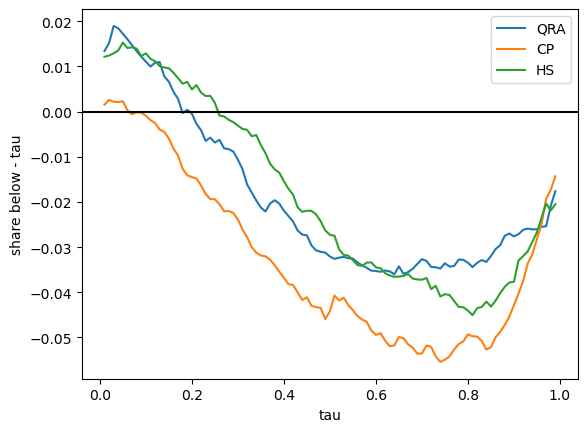

error correlation 12-13 h 0.96, 3-19 h 0.13


In [13]:
TAUS = np.arange(1, 100) / 100; W_QRA, W_ERR = 182, 112
FA, FL_ = PT['aw_arx'], PT['aw_lear']
WEEK0 = list(range(N_BURN, len(FDAYS), 7))


def qra_hour(h):
    import warnings as _w
    _w.filterwarnings("ignore")                                 # iteration-limit warnings at the extreme quantiles
    out = np.full((len(FDAYS), len(TAUS)), np.nan)
    for w in WEEK0:
        tr = np.arange(w - W_QRA, w)
        assert tr.max() < w and tr.min() >= 0                     # past forecasts only
        X = sm.add_constant(np.column_stack([FA[tr, h], FL_[tr, h]]))
        y = ACT_F[tr, h]
        te = np.arange(w, min(w + 7, len(FDAYS)))
        Xt = sm.add_constant(np.column_stack([FA[te, h], FL_[te, h]]), has_constant="add")
        for j, tau in enumerate(TAUS):
            b = QuantReg(y, X).fit(q=tau, max_iter=5000).params
            out[te, j] = Xt @ b
    return out


QRA = np.sort(np.stack(Parallel(n_jobs=-1)(delayed(qra_hour)(h) for h in range(24)), 1)[TI], axis=2)
ERR_L = ACT_F - FL_
CPQ = np.zeros((len(TDAYS), 24, 99)); HSQ = np.zeros_like(CPQ)
for k, t in enumerate(TI):
    win = ERR_L[t - W_ERR:t]
    for j, tau in enumerate(TAUS):
        HSQ[k, :, j] = FL_[t] + np.quantile(win, tau, axis=0)
        CPQ[k, :, j] = FL_[t] + np.sign(tau - 0.5) * np.quantile(np.abs(win), abs(2 * tau - 1), axis=0)


def prob_scores(Q):
    y = A[:, :, None]
    ps = (((y < Q).astype(float) - TAUS[None, None, :]) * (Q - y)).mean()
    lo50, hi50, lo90, hi90 = Q[:, :, 24], Q[:, :, 74], Q[:, :, 4], Q[:, :, 94]
    c50 = ((A >= lo50) & (A <= hi50)).mean()
    inside90 = (A >= lo90) & (A <= hi90)
    n, x = inside90.size, int((~inside90).sum())
    ph = x / n
    lr = -2 * ((n - x) * np.log(0.9) + x * np.log(0.1) - ((n - x) * np.log(1 - ph) + x * np.log(ph)))
    rel = [((A <= Q[:, :, j]).mean()) for j in range(len(TAUS))]
    g_ = (~inside90).mean(axis=1) - 0.1                         # daily miss share: robust to dependence within the day
    z_ = g_.mean() / np.sqrt(nw_var(g_, 7) / len(g_))
    return {"aps": ps, "c50": c50 * 100, "c90": inside90.mean() * 100, "w90": (hi90 - lo90).mean(), "kupiec": lr,
            "kupiec_p": 1 - stats.chi2.cdf(lr, 1), "hac_z": z_, "hac_p": 2 * stats.norm.sf(abs(z_)), "rel": rel}


for nm, Qx in [('QRA', QRA), ('CP', CPQ), ('HS', HSQ)]:
    r = prob_scores(Qx); print(nm, {k: round(v, 3) for k, v in r.items() if k != 'rel'})
    plt.plot(TAUS, np.array(r['rel']) - TAUS, label=nm)
plt.axhline(0, color='k'); plt.legend(); plt.xlabel('tau'); plt.ylabel('share below - tau'); plt.show()
c = np.corrcoef((A - M['aw_lear']).T); print('error correlation 12-13 h %.2f, 3-19 h %.2f' % (c[12, 13], c[3, 19]))

## §8 Cointegrare: România–Ungaria (zilnic) și energie–gaze–hidro (lunar)

In [14]:
DLY = PD.loc[START:END, ['RO', 'HU', 'DE_LU']].dropna()
for z in ['RO', 'HU', 'DE_LU']: print('ADF p, level', z, round(adfuller(DLY[z], autolag='AIC')[1], 4))
for z in ['HU', 'DE_LU']:
    eg = coint(DLY['RO'], DLY[z], trend='c', autolag='aic'); jo = coint_johansen(DLY[['RO', z]].values, det_order=0, k_ar_diff=6)
    u = sm.OLS(DLY['RO'], sm.add_constant(DLY[z])).fit().resid; phi = sm.OLS(u.values[1:], u.values[:-1]).fit().params[0]
    print(z, 'Engle-Granger %.2f (5%% cv %.2f) | Johansen trace %s vs %s | half-life %.1f days' % (
          eg[0], eg[2][1], jo.lr1.round(2), jo.cvt[:, 1].round(2), np.log(0.5) / np.log(phi)))
hyd = GH[['hydro_run_of_river', 'hydro_water_reservoir']].sum(axis=1, min_count=2); hyd.index = pd.to_datetime(hyd.index, utc=True)
hyd = hyd[hyd.index < (END + pd.Timedelta(days=1)).tz_localize(TZ).tz_convert('UTC')]
hyd_m = hyd.tz_convert(TZ).resample('MS').sum(min_count=600) / 1e6; hyd_m.index = hyd_m.index.tz_localize(None)
TTF = pd.read_csv(DATA + 'ttf_monthly.csv'); TTF.index = pd.PeriodIndex(TTF['month'], freq='M').to_timestamp()
MD = pd.concat([PD['RO'].loc[:END].resample('MS').mean().rename('price'), TTF['ttf_eur_mwh'].rename('ttf'), hyd_m.rename('hydro')], axis=1).dropna()
MD['hydro_ds'] = MD['hydro'] - MD.groupby(MD.index.month)['hydro'].transform('mean')
eg1 = coint(MD['price'], MD['ttf'], trend='c', autolag='aic'); lr = sm.OLS(MD['price'], sm.add_constant(MD[['ttf']])).fit()
ecm_df = pd.DataFrame({'dp': MD['price'].diff(), 'u1': lr.resid.shift(1), 'dttf': MD['ttf'].diff(), 'hyd': MD['hydro_ds']}).dropna()
ecm = sm.OLS(ecm_df['dp'], sm.add_constant(ecm_df[['u1', 'dttf', 'hyd']])).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
print('price-TTF Engle-Granger %.2f (cv %.2f); beta %.3f (efficiency %.1f%%)' % (eg1[0], eg1[2][1], lr.params['ttf'], 100 / lr.params['ttf']))
print(ecm.summary().tables[1])

ADF p, level RO 0.0636
ADF p, level HU 0.0517


ADF p, level DE_LU 0.0148
HU Engle-Granger -10.58 (5% cv -3.34) | Johansen trace [139.69   6.21] vs [15.49  3.84] | half-life 0.8 days


DE_LU Engle-Granger -5.79 (5% cv -3.34) | Johansen trace [128.2    6.58] vs [15.49  3.84] | half-life 1.5 days


price-TTF Engle-Granger -5.64 (cv -3.38); beta 1.947 (efficiency 51.4%)


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3231      1.382      0.234      0.815      -2.386       3.032
u1            -0.4518      0.084     -5.394      0.000      -0.616      -0.288
dttf           2.1245      0.167     12.701      0.000       1.797       2.452
hyd          -12.8039      4.125     -3.104      0.002     -20.888      -4.720


## §9 Studii de caz: lună cu lună, săptămîna de criză, prețuri pe 15 minute, baterie și cumpărător flexibil

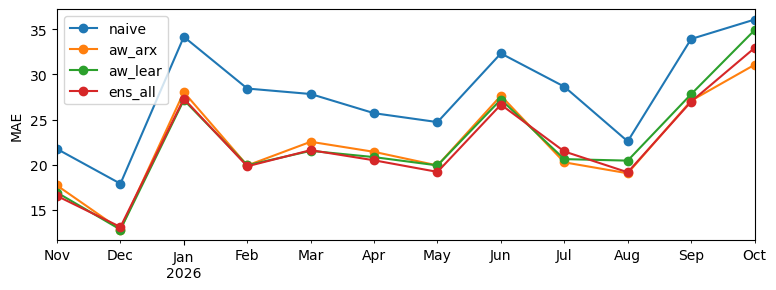

stress week from 2026-10-19 {'naive': np.float64(40.19), 'aw_lear': np.float64(36.54), 'gbm': np.float64(34.35), 'ens_all': np.float64(34.95)}


15-min MAE: flat 26.02, with intra-hour shape 24.53 (363 days)
naive battery 84623 EUR per MW (84.9% of perfect) | flexible buyer 71.74 EUR/MWh
aw_arx battery 88776 EUR per MW (89.0% of perfect) | flexible buyer 68.67 EUR/MWh
aw_lear battery 89568 EUR per MW (89.8% of perfect) | flexible buyer 67.87 EUR/MWh


gbm battery 89184 EUR per MW (89.5% of perfect) | flexible buyer 68.93 EUR/MWh
ens_all battery 90738 EUR per MW (91.0% of perfect) | flexible buyer 68.09 EUR/MWh
fixed 8-12 h block 100.59 EUR/MWh


In [15]:
bym[['naive', 'aw_arx', 'aw_lear', 'ens_all']].plot(marker='o', figsize=(9, 3)); plt.ylabel('MAE'); plt.show()
mons = [t for t in TDAYS if t.dayofweek == 0 and t + pd.Timedelta(days=6) <= END]
SW = max(mons, key=lambda t: A[POS[t] - N_BURN:POS[t] - N_BURN + 7].mean()); sw = slice(POS[SW] - N_BURN, POS[SW] - N_BURN + 7)
print('stress week from', SW.date(), {k: round(np.abs(A[sw] - M[k][sw]).mean(), 2) for k in ['naive', 'aw_lear', 'gbm', 'ens_all']})
X = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', index_col=0)['RO'].dropna(); X.index = pd.to_datetime(X.index, utc=True).tz_convert(TZ)
X = X.loc[str((TEST0 - pd.Timedelta(days=40)).date()):str(END.date())]
ALLQ = {d: g.values for d, g in X.groupby(X.index.tz_localize(None).normalize()) if len(g) == 96}
QD = [t for t in TDAYS if t in ALLQ and not DST.loc[t]]
Q = np.array([ALLQ[t] for t in QD])
flat = np.repeat(np.array([M['aw_lear'][POS[t] - N_BURN] for t in QD]), 4, axis=1)
shape = np.array([np.mean([ALLQ[t - pd.Timedelta(days=j)] - np.repeat(ALLQ[t - pd.Timedelta(days=j)].reshape(24, 4).mean(1), 4)
                           for j in range(1, 29) if t - pd.Timedelta(days=j) in ALLQ], 0) for t in QD])
print('15-min MAE: flat %.2f, with intra-hour shape %.2f (%d days)' % (np.abs(Q - flat).mean(), np.abs(Q - flat - shape).mean(), len(QD)))


def battery(F, Aa, eta=0.9):
    """1 MW / 2 MWh battery, one cycle a day: charge in a 2-hour block, discharge in a later 2-hour block, both chosen on the
    forecast; trade only if the forecast spread pays the losses. Profit in EUR, valued at actual prices."""
    prof = np.zeros(len(F))
    for k in range(len(F)):
        f, a = F[k], Aa[k]
        bestv, bs = 0.0, None
        for i in range(0, 21):
            for j in range(i + 2, 23):
                v = eta * (f[j] + f[j + 1]) - (f[i] + f[i + 1])
                if v > bestv:
                    bestv, bs = v, (i, j)
        if bs:
            i, j = bs
            prof[k] = eta * (a[j] + a[j + 1]) - (a[i] + a[i + 1])
    return prof


def flex(F, Aa, L=4, fixed=8):
    """Flexible process of 1 MW for L consecutive hours a day: start chosen on the forecast; cost in EUR at actual prices."""
    cost, base = np.zeros(len(F)), np.zeros(len(F))
    for k in range(len(F)):
        s = int(np.argmin([F[k][i:i + L].sum() for i in range(24 - L + 1)]))
        cost[k] = Aa[k][s:s + L].sum()
        base[k] = Aa[k][fixed:fixed + L].sum()
    return cost, base


ND = ~DST.loc[TDAYS].values; AN = A[ND]   # DST days left out: their 24 columns are not 24 physical hours
for k in ['naive', 'aw_arx', 'aw_lear', 'gbm', 'ens_all']:
    b_ = battery(M[k][ND], AN).sum()
    print(k, 'battery %.0f EUR per MW (%.1f%% of perfect) | flexible buyer %.2f EUR/MWh' % (
          b_, b_ / battery(AN, AN).sum() * 100, flex(M[k][ND], AN)[0].sum() / (4 * len(AN))))
print('fixed 8-12 h block %.2f EUR/MWh' % (flex(AN, AN)[1].sum() / (4 * len(AN))))

## §10 Autoverificarea scurgerii de informație
(a) fiecare intrare este publică înainte de ora 12:00 CET din *d−1*; (b) prognozele recalculate după ștergerea tuturor prețurilor din *d* și a tuturor fundamentalelor din *d−1* nu trebuie să se schimbe.

In [16]:
def avail_time(src, lag, t):
    row = t - pd.Timedelta(days=lag)
    if src == "price":        # the auction for delivery day `row` closes 12:00 CET on row-1; results published about 13:00
        return row - pd.Timedelta(days=1) + pd.Timedelta(hours=13)
    if src == "realised":     # metered day `row` is complete at 24:00 of `row`
        return row + pd.Timedelta(days=1)
    if src == "close":        # carbon ETC close on trading day `row` (London, 16:30 local = 17:30 CET)
        return row + pd.Timedelta(hours=17, minutes=30)
    raise ValueError(src)


REG = [('P', k, 'price') for k in PLAGS] + [('L', k, 'realised') for k in XLAGS] + [('R', k, 'realised') for k in XLAGS] + \
      [('fund_' + c, 2, 'close' if c == 'eua' else 'realised') for c in FUND_RAW.columns]
n = 0
for t in FDAYS:
    cut = t - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
    for blk, lag, src in REG:
        assert avail_time(src, lag, t) <= cut, (blk, lag, t); n += 1
print('timestamp audit passed:', n, 'checks')


def corrupt(i, fill=np.nan):
    """Data as a function sees them if everything after gate closure is deleted (fill=NaN) or replaced by nonsense (finite fill)."""
    Pc, Lc, Rc = P_.copy(), L_.copy(), R_.copy()
    Pc[i:] = fill                                               # prices of day d and later unknown
    Lc[i - 1:] = fill                                           # realised quantities of d-1 and later unknown
    Rc[i - 1:] = fill
    raw = FUND_RAW.copy()
    raw.loc[CAL[i - 1]:] = fill
    return Pc, Lc, Rc, raw.ffill().shift(2).reindex(CAL).values.astype(float)


for t in [TDAYS[0], TDAYS[-1]]:
    i = IDX[t]; r = point_day(*corrupt(i), i)
    d_ = max(np.max(np.abs(np.asarray(r[k]) - PT[k][POS[t]])) for k in names)
    print(t.date(), 'max change after deleting future data: %.2e' % d_); assert d_ < 1e-6
a0, _ = MB[-1]; i = IDX[TDAYS[-1]]
print('GBM change %.2e' % np.max(np.abs(gbm_month(*corrupt(i), a0, i)[0][-1] - M['gbm'][-1])))
print('leakage self-check PASSED')

timestamp audit passed: 7658 checks


2025-11-01 max change after deleting future data: 2.27e-13


2026-10-31 max change after deleting future data: 7.39e-13


GBM change 0.00e+00
leakage self-check PASSED
